# LLM Evaluation 1 of 4: What Can a Score Really Tell Us?

You ask an assistant why Mei-Lin keeps a pendant. The passage says it contains a letter
proving her family claim to a trade route.

- **Answer A:** the letter confirms her family line and helps her recover that route.
- **Answer B:** the pendant is a valuable heirloom showing her family's social status.

We want A: it keeps the information that answers the question. B sounds plausible, but the
passage does not support its explanation. A score based on familiar words does not
automatically know that difference.

That is our starting problem. A **metric** is a rule for turning one check into a number.
Before trusting the number, ask: **what did this rule actually check?**

We will inspect simple examples, then let a real CPU model answer the same four Riverside
questions. We build one word-matching rule ourselves and use libraries for the other scores.
These four practice cases help us understand the checks; they are not enough to certify a model.

### Follow the problem, not a list of metric names

| Stop | What are we trying to find out? | What could this check still miss? |
| --- | --- | --- |
| 1 | Did the answer keep the reference wording and order? | Different wording can still be correct |
| 2 | Can we allow familiar words with similar meanings? | An on-topic answer can still change a fact |
| 3 | Did the wording look expected to a language model? | A false statement can also sound familiar |
| 4 | What happens when a real model writes the answers? | Good similarity scores need not mean supported claims |
| 5 | Is an overall gain hiding a failure on one kind of question? | An average cannot tell us which requests still fail |

The code uses a few names worth knowing:

- **Context:** the passage supplied with the question.
- **Reference:** an accepted answer we compare against, not the only possible correct wording.
- **`candidate` / `fluent_wrong`:** prewritten practice answers, labeled for this lesson.
  The model's own answers arrive in Part 4.
- **Slice:** a group of similar questions, such as questions about a policy.

We calculate ROUGE-1/2/L, BLEU-4, METEOR, BERTScore and reference perplexity.
ROUGE-S and BLEU-1/2/3 are compared in words, not separately run.

**Before running:** use the adjacent setup script. The real run uses four CPU threads.
On first use, missing public model files and English WordNet are downloaded to user caches;
later runs reuse them. The answers are generated on your machine, not sent to an inference API.

In [ ]:
# Deterministic setup and shared Riverside cases.
import math
from pathlib import Path
import sys

CHAPTER = Path.cwd()
if not (CHAPTER / "evaluation_shared.py").is_file():
    CHAPTER = CHAPTER / "learning" / "08-llm-evaluation"
if not (CHAPTER / "evaluation_shared.py").is_file():
    raise FileNotFoundError("Start this notebook from the repository root or its evaluation chapter.")
sys.path.insert(0, str(CHAPTER))
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from evaluation_shared import (
    COURSE_CAVEAT, RIVERSIDE_CASES, assert_fixture_contracts,
    normalized_terms, set_seed, tokenize,
)

set_seed()
assert_fixture_contracts()
print(COURSE_CAVEAT)
display(pd.DataFrame(RIVERSIDE_CASES)[["id", "query", "slice"]])


## Part 1 - Which words survived, and in what order?

First shrink the pendant answer so the matching is easy to see:

- **Reference:** `the pendant hides a letter`
- **Answer:** `the pendant hides a small letter`

The five reference words are still there. But inserting `small` breaks the neighboring
pair `a letter`. A word checklist and a phrase checklist will therefore see different things.
Neither tells us whether the new detail, `small`, is supported by the passage.

### Related ROUGE choices are different ways of counting

| Choice | What does it look for? | What can get past it? |
| --- | --- | --- |
| ROUGE-1 | Individual reference words in the answer | The same words in a different order |
| ROUGE-2 | Neighboring pairs, such as `a letter` | An inserted word breaks a pair even when the main fact survives |
| ROUGE-L | Words kept in the same order, allowing words between them | A correct synonym may not match at all |
| ROUGE-S | Ordered pairs with gaps allowed | It still checks wording, not facts; the gap policy must be stated |

These are related views, not a rule that a later letter or larger number is always better.
We implement ROUGE-L once; the library handles the other measured choices.

### One set of matches, three questions

For this word-based example:

| Reading | Question it answers | Pendant example |
| --- | --- | --- |
| Precision | Of the words I produced, how many matched? | Five out of six |
| Recall | Of the reference words, how many did I recover? | Five out of five |
| F1 | Did I do reasonably well on both? | About 0.91 |

Extra wording can lower precision; missing wording can lower recall.
That is a description of the match, not a judgment that every extra word was useless.

Follow the illustration, then open the code. The longest chain of matching words that
keeps its order is called the **longest common subsequence**, or LCS. ROUGE-L uses that count.

### See what changed when we inserted one word

Follow the gold links. All five reference words remain in order, while the pair `a letter` no longer appears next to itself. These are counts from the short example, not scores for a model-generated answer.

![The reference the pendant hides a letter is compared with the pendant hides a small letter. Word matching recovers five reference words; adjacent-pair matching retains three of four reference pairs; ordered matching retains all five while skipping small. A reordered answer has all the same words but an ordered match of only two.](attachment:01-metrics-rouge.png)

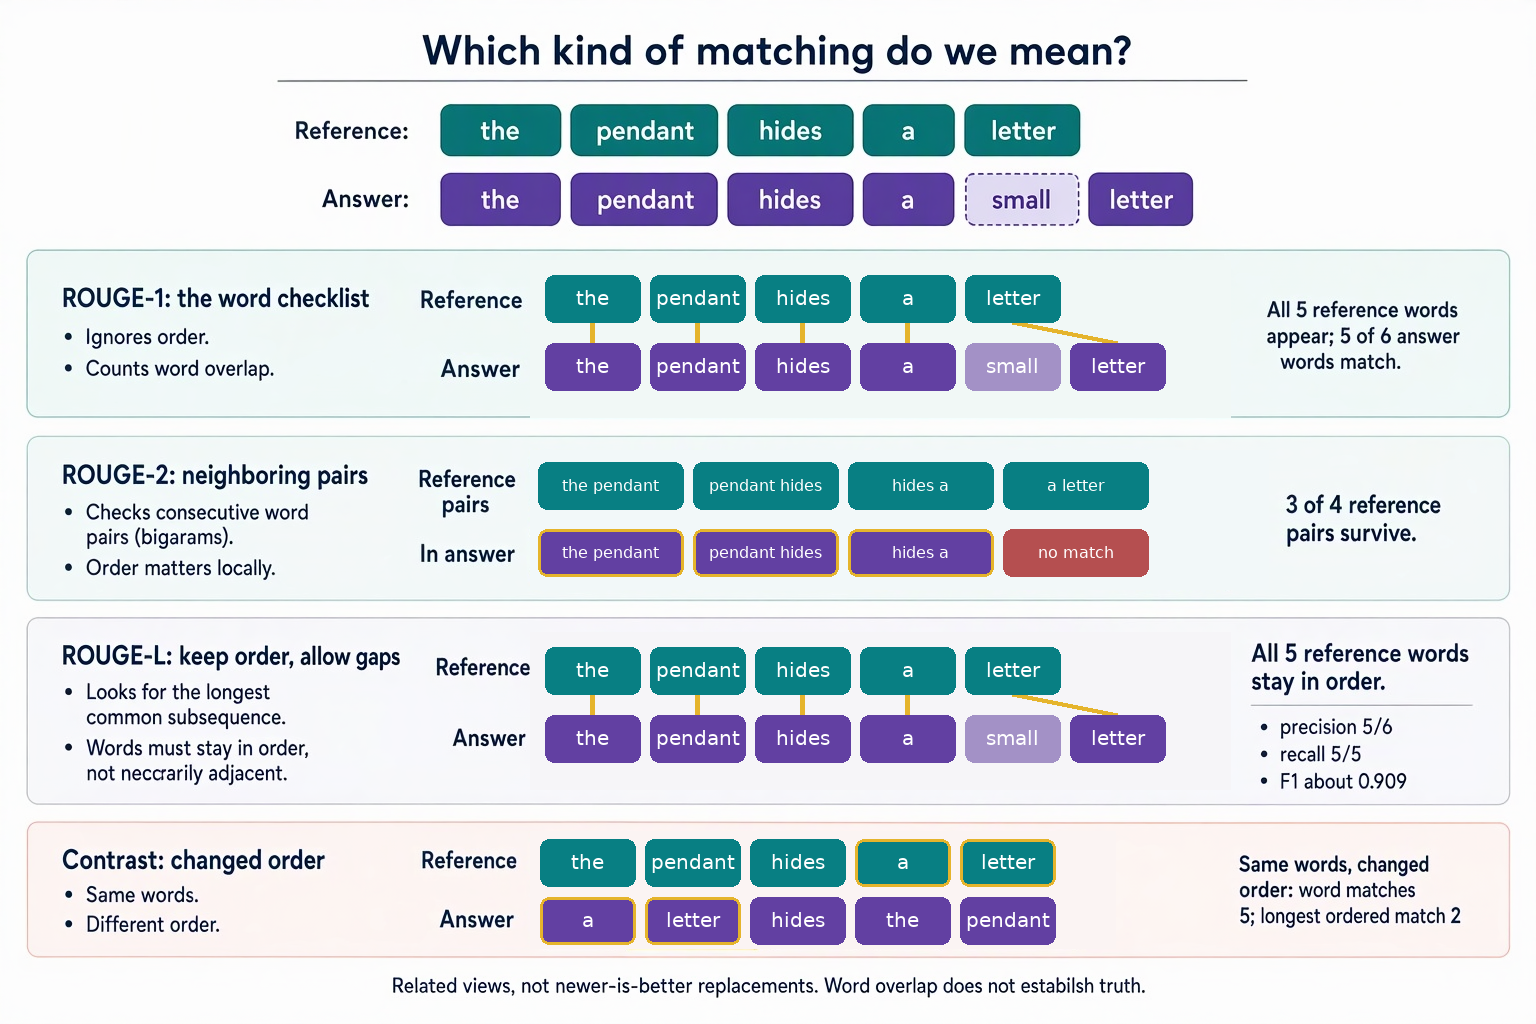

In [ ]:
# ROUGE-L from scratch: longest common subsequence plus F1.
def lcs_length(left, right):
    table = np.zeros((len(left) + 1, len(right) + 1), dtype=int)
    for i, left_token in enumerate(left, start=1):
        for j, right_token in enumerate(right, start=1):
            table[i, j] = (
                table[i - 1, j - 1] + 1
                if left_token == right_token
                else max(table[i - 1, j], table[i, j - 1])
            )
    return int(table[-1, -1])

def rouge_l(candidate, reference):
    candidate_tokens, reference_tokens = tokenize(candidate), tokenize(reference)
    overlap = lcs_length(candidate_tokens, reference_tokens)
    precision = overlap / max(len(candidate_tokens), 1)
    recall = overlap / max(len(reference_tokens), 1)
    return 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)

# Other ROUGE views keep this answer/reference interface:
# library RougeScorer(["rouge1", "rouge2"]) swaps ordered matches for word/group counts.
# We do not write three more almost-identical scorers.


### Read the grid as two unfinished sentences

`table[i, j]` asks: how many words can we match while keeping order, using only
the first `i` words on one side and the first `j` on the other?

- If the current words match, extend the earlier chain by one.
- If they do not, keep the better chain found by skipping a word on either side.

The bottom-right entry is the final count. `rouge_l` turns that count into
precision, recall and F1. The next cell checks our arithmetic against the library
using the same word-splitting rule, so tokenization does not explain away a difference.

In [ ]:
from rouge_score import rouge_scorer
from evaluation_metrics import LessonTokenizer

example_reference = "the pendant hides a letter"
example_answer = "the pendant hides a small letter"
library_rouge = rouge_scorer.RougeScorer(["rougeL"], tokenizer=LessonTokenizer())
library_value = library_rouge.score(example_reference, example_answer)["rougeL"].fmeasure
assert np.isclose(rouge_l(example_answer, example_reference), library_value)
print(f"Five ordered reference words survive; ROUGE-L F1 = {library_value:.3f}.")

### But what if the correct answer uses a different word?

`Reclaim the route` and `recover the route` can describe the same useful information.
Exact matching treats `reclaim` and `recover` as strangers.

For our next small attempt, put chosen related words into the same bucket, then count
the buckets each sentence uses. The code calls the resulting comparison `semantic_cosine`.
Here that is just a comparison of manually grouped word counts: no model learned the
groups, and no part of it checks whether the relationships in the sentence are supported.

**Predict:** will this help the valid paraphrase without also helping the unsupported answer?

In [ ]:
# Hand-mapped word-count cosine: a toy, not contextual BERTScore.
vocabulary = sorted({
    term for case in RIVERSIDE_CASES
    for field in ["reference", "candidate", "fluent_wrong"]
    for term in normalized_terms(case[field])
})
term_index = {term: index for index, term in enumerate(vocabulary)}

def semantic_vector(text):
    vector = torch.zeros(len(vocabulary), dtype=torch.float32)
    for term in normalized_terms(text):
        if term in term_index:
            vector[term_index[term]] += 1
    return torch.nn.functional.normalize(vector, dim=0) if vector.norm() else vector

def semantic_cosine(left, right):
    return torch.dot(semantic_vector(left), semantic_vector(right)).item()

print("semantic vector shape:", tuple(semantic_vector(RIVERSIDE_CASES[0]["reference"]).shape))


In [ ]:
# Compare correct paraphrases with fluent factual errors.
metric_rows = []
for case in RIVERSIDE_CASES:
    for answer_type in ["candidate", "fluent_wrong"]:
        answer = case[answer_type]
        metric_rows.append({
            "case": case["id"], "answer_type": answer_type,
            "rouge_l": rouge_l(answer, case["reference"]),
            "semantic_cosine": semantic_cosine(answer, case["reference"]),
        })
metric_table = pd.DataFrame(metric_rows)
display(metric_table.round(3))


### Did allowing related words help?

Look at the two `award` rows. The prewritten wrong answer changes `longlisted` to `won`,
but keeps the author, year and prize.

- ROUGE-L gives it **0.609**, above the valid paraphrase's **0.526**. Familiar wording wins here.
- Our word-grouping toy ranks the valid paraphrase higher: **0.843** versus **0.735**.
  That is useful, but the wrong claim still shares many of the same words.

Grouping words helped with rephrasing. It did not turn the scorer into a fact checker.
We know which practice answer is wrong because it is labeled, not because cosine similarity
discovered the mistake.

**Keep the distinction:** this is a manually grouped word-count toy, not BERTScore.
Part 4 uses a pretrained model to compare words in their sentence context.

## Part 2 - Familiar wording can still tell the wrong story

Try reading a familiar sentence and guessing each next word. A language model does
something similar: it assigns probabilities to the tokens that follow.
**Perplexity** summarizes how surprised it was by the tokens it actually saw.
Lower means those tokens were more expected, not that the statement was more accurate.

Our first version is deliberately small. It counts how often one word follows another
in the supplied passages. A pair of neighboring words is a **bigram**.
The code gives unseen pairs a small allowance rather than assigning them zero probability,
then combines the token losses into one perplexity value.

This count model is a teaching example, not a general English fluency judge.
Compare its two answers to the same question; do not compare its absolute numbers with
the different model and tokenizer used in Part 4.

In [ ]:
# Fit a transparent count language model on context text only.
bigram_counts = Counter()
context_counts = Counter()
for case in RIVERSIDE_CASES:
    tokens = ["<s>"] + tokenize(case["context"]) + ["</s>"]
    for left, right in zip(tokens, tokens[1:]):
        bigram_counts[(left, right)] += 1
        context_counts[left] += 1
lm_vocabulary = {token for pair in bigram_counts for token in pair}

def perplexity(text):
    tokens = ["<s>"] + tokenize(text) + ["</s>"]
    losses = []
    for left, right in zip(tokens, tokens[1:]):
        probability = (
            bigram_counts[(left, right)] + 1
        ) / (context_counts[left] + len(lm_vocabulary))
        losses.append(-math.log(probability))
    return math.exp(float(np.mean(losses)))


In [ ]:
# Fluency can look healthy for both correct and false answers.
perplexity_rows = []
for case in RIVERSIDE_CASES:
    perplexity_rows.append({
        "case": case["id"],
        "candidate_ppl": perplexity(case["candidate"]),
        "wrong_ppl": perplexity(case["fluent_wrong"]),
    })
perplexity_table = pd.DataFrame(perplexity_rows)
display(perplexity_table.round(2))
print("Perplexity measures average surprise under this tiny model, never factual accuracy.")


### Read the award row before moving on

The valid paraphrase has toy perplexity about **41.90**; the wrong answer has **39.03**.
Lower is less surprising to this count model, so it favors the wrong wording here.

There is no paradox. The model counted local word patterns; it never checked whether
`won` follows from the passage. This is a result from the little experiment, not a claim
that every false answer will get low perplexity.

## Part 3 - A disagreement tells us where to look

The award answer looked good to the word matcher and familiar to the count model.
Neither check asked whether the passage actually said the author won.

Do not average that disagreement out of sight. Keep each question's scores together
so you can ask **which check noticed the problem, and which one could not see it?**

The next table adds a review marker to some already-labeled wrong answers.
Its `0.45` cutoff is a chosen teaching value, not a validated safety threshold.
Because the marker uses the supplied `fluent_wrong` label, it is not a detector for
mistakes in new, unlabeled answers.

In [ ]:
# One table keeps all instrument readings at item level.
disagreement = metric_table.merge(
    perplexity_table.melt(
        id_vars="case", var_name="ppl_type", value_name="perplexity"
    ).assign(
        answer_type=lambda frame: frame["ppl_type"].map({
            "candidate_ppl": "candidate", "wrong_ppl": "fluent_wrong"
        })
    )[["case", "answer_type", "perplexity"]],
    on=["case", "answer_type"],
)
disagreement["needs_claim_review"] = (
    (disagreement["semantic_cosine"] >= 0.45)
    & (disagreement["answer_type"] == "fluent_wrong")
)
display(disagreement.round(3))


In [ ]:
# Static evidence: change one answer type across all instruments.
plot_data = disagreement.set_index(["case", "answer_type"])[["rouge_l", "semantic_cosine"]]
plot_data.plot.bar(figsize=(10, 4))
plt.title("Reference and semantic metrics disagree by answer")
plt.ylim(0, 1.05)
plt.ylabel("score")
plt.tight_layout()
plt.show()


<a id="real-cpu-evaluation"></a>

## Part 4 - Now let a model write the answers

So far we supplied both the valid and unsupported practice answers.
A real model can fail in ways we did not write down in advance. Give it the same four
questions, keep what it actually says, and run the checks on those answers.

Two models have different jobs:

| Job | Model used here |
| --- | --- |
| Read the passage and question, then write an answer | SmolLM2-135M-Instruct |
| Turn words in their sentence context into lists of numbers that BERTScore can compare | DistilBERT |

Both run on CPU. We fix their saved revisions so a later download does not quietly
change the experiment. BERTScore values from a different encoder or layer are not
directly comparable with these values.

The prompt contains **the passage and question, not the reference answer**.
The context is meant to provide the facts; withholding the reference checks whether
the model can answer rather than simply being given the answer key.

<details>
<summary>Optional: use a model saved in an earlier chapter</summary>

A checkpoint is a saved model; an adapter saves only changes to a base model.
The next cell lists public and local choices, then explicitly selects the public model.
For a complete Stage 06 HF checkpoint or adapter, choose `MODEL_SOURCE = "local"` and
set `LOCAL_PATH`. The helper loads an adapter's declared base when needed.
A missing selected artifact raises an error; it does not become a different model.
Stage 05's custom PyTorch training packages need their own loader.
Check the earlier training data before treating these visible course questions as an
independent test of your saved model.

</details>

We do not train or choose a checkpoint on these four questions. They remain a small,
visible practice set, not a sealed test of broad capability.

In [ ]:
from evaluation_metrics import (
    ENCODER_ID, ENCODER_REVISION, download_snapshot, generate_cases,
    load_eval_model, local_checkpoint_inventory, model_options, prepare_wordnet, score_answers,
)

display(pd.DataFrame(model_options()))
display(pd.DataFrame(local_checkpoint_inventory()))
MODEL_SOURCE = "hf"
LOCAL_PATH = None
# For an earlier adapter, choose "local" and uncomment this path:
# LOCAL_PATH = CHAPTER.parent / "06-llm-finetuning" / "checkpoints" / "preference-dpo"
# Broken selected checkpoints raise; they do not secretly become a different model.
torch.set_num_threads(4)
model, tokenizer, model_identity = load_eval_model(MODEL_SOURCE, LOCAL_PATH)
print("Model actually selected:", model_identity)

In [ ]:
measured_answers = generate_cases(model, tokenizer, RIVERSIDE_CASES)
display(pd.DataFrame(measured_answers)[["id", "query", "reference", "answer"]])
del model

### Same answers, different things to notice

The model has now written its own answers. We could count exact words, allow related
word forms, or ask a pretrained model which tokens look close in context.
Those are different checks, not interchangeable routes to a universal quality score.

| Method | What problem does it address? | What does it do? | What can it still miss? |
| --- | --- | --- | --- |
| BLEU | Repeated words and tiny answers can flatter a naive match count | Cap repeated credit, combine phrase matches, and penalize very short output | Valid answers using different wording |
| METEOR | `Recovered` and `recover` should not be complete strangers | Match exact words, stems and synonyms; reduce credit for scattered matches | A related word can still change a fact |
| BERTScore | The surrounding sentence changes what a word means | Compare token representations learned from context | A close-sounding answer can still lack support |

A **stem** groups forms of a word; a **synonym** is a word with a related meaning.
The next diagrams show the matches rather than asking you to remember the labels.

### BLEU's numbered versions change the phrase length

| Setting | Which word groups are checked? | What becomes stricter? |
| --- | --- | --- |
| BLEU-1 | Individual words | Very little word order is checked |
| BLEU-2 | Words and neighboring pairs | More short phrases must match |
| BLEU-3 | Add three-word groups | Small rewordings break more groups |
| BLEU-4, used here | Add four-word groups | Closer phrasing is rewarded, not deeper truth |

All still need capped counts and a short-answer penalty. Library smoothing prevents one
missing long phrase from wiping out the entire score. Effective order avoids requiring
four-word groups from an answer that has fewer than four words.

For translation, BLEU remains a comparison baseline alongside learned checks such as
COMET/xCOMET or MetricX and human review. For open-ended questions, check task success
and support from the evidence. ROUGE-1/2/L remain useful quick wording checks;
METEOR is an older optional comparison, not a release decision by itself.

### One match is not an unlimited supply of credit

On the left, the reference contains `letter` once: repeating it three times does not create three reference matches. On the right, one matching word is not a complete answer. The diagram separates those two safeguards; it is not a full BLEU-4 calculation.

![A single reference occurrence of letter gives only one match to letter letter letter. A separate one-word answer letter matches but omits most of the five-word reference, so it receives a small brevity penalty. A bottom strip distinguishes BLEU word-group lengths.](attachment:01-metrics-bleu.png)

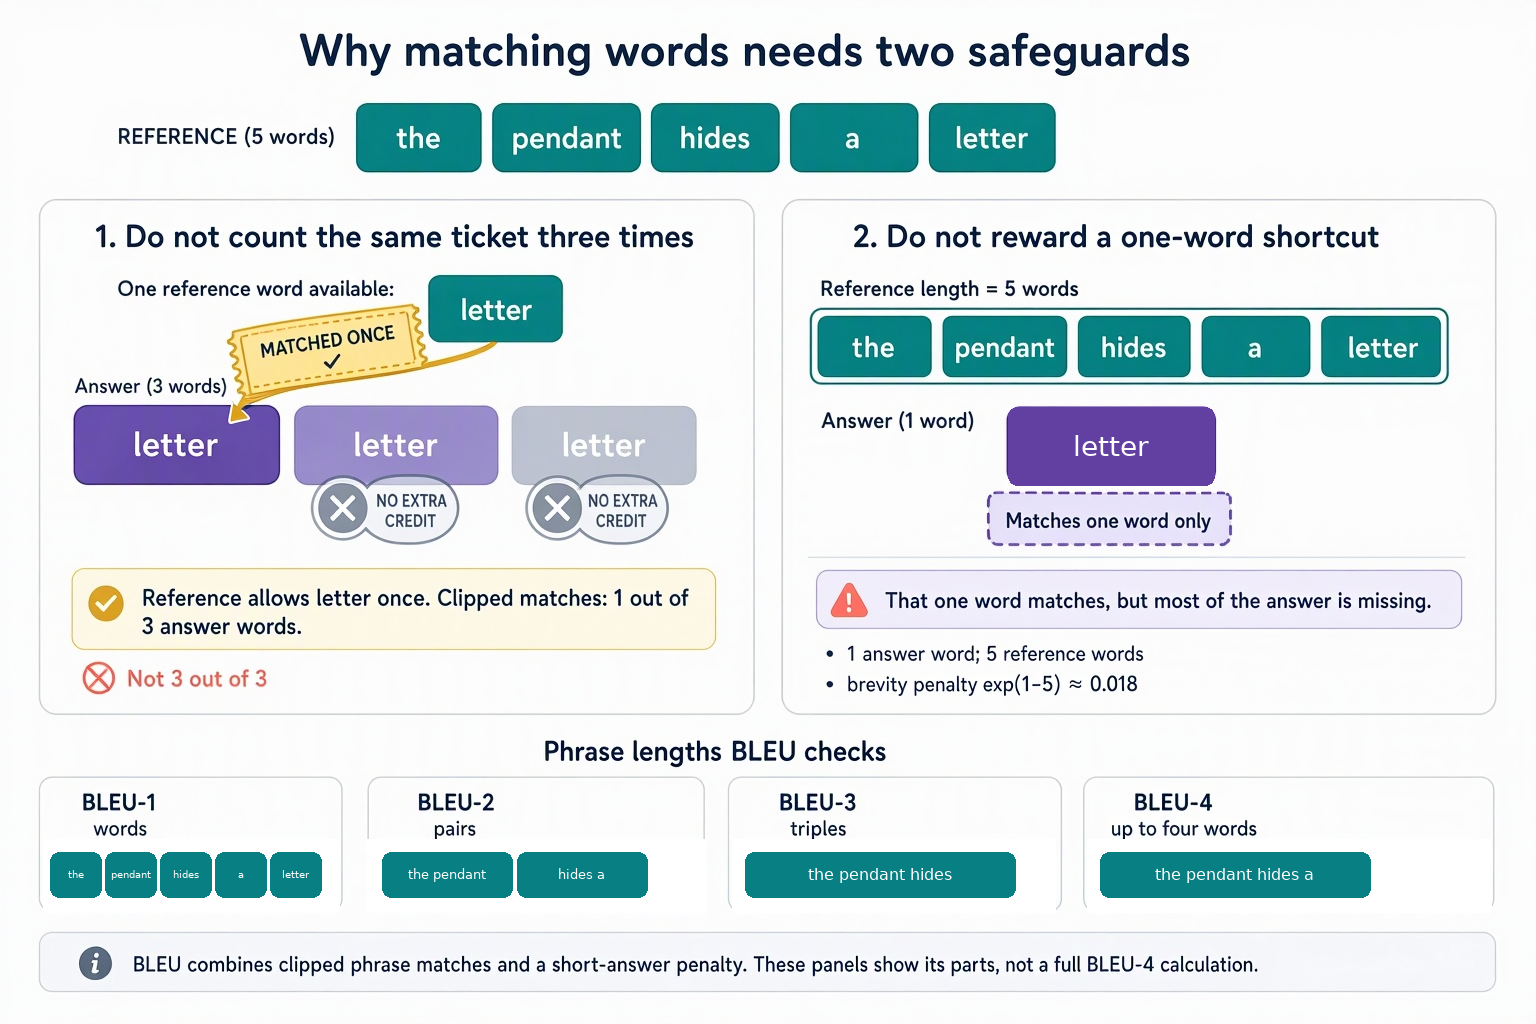

### The right words still need to hang together

The upper answer uses `conceals` where the reference uses `hides`, and the matches still run in order. The lower answer scatters the same words. Each unbroken run is a chunk; more separate chunks mean a larger penalty. The shown NLTK scores come from these small constructed examples.

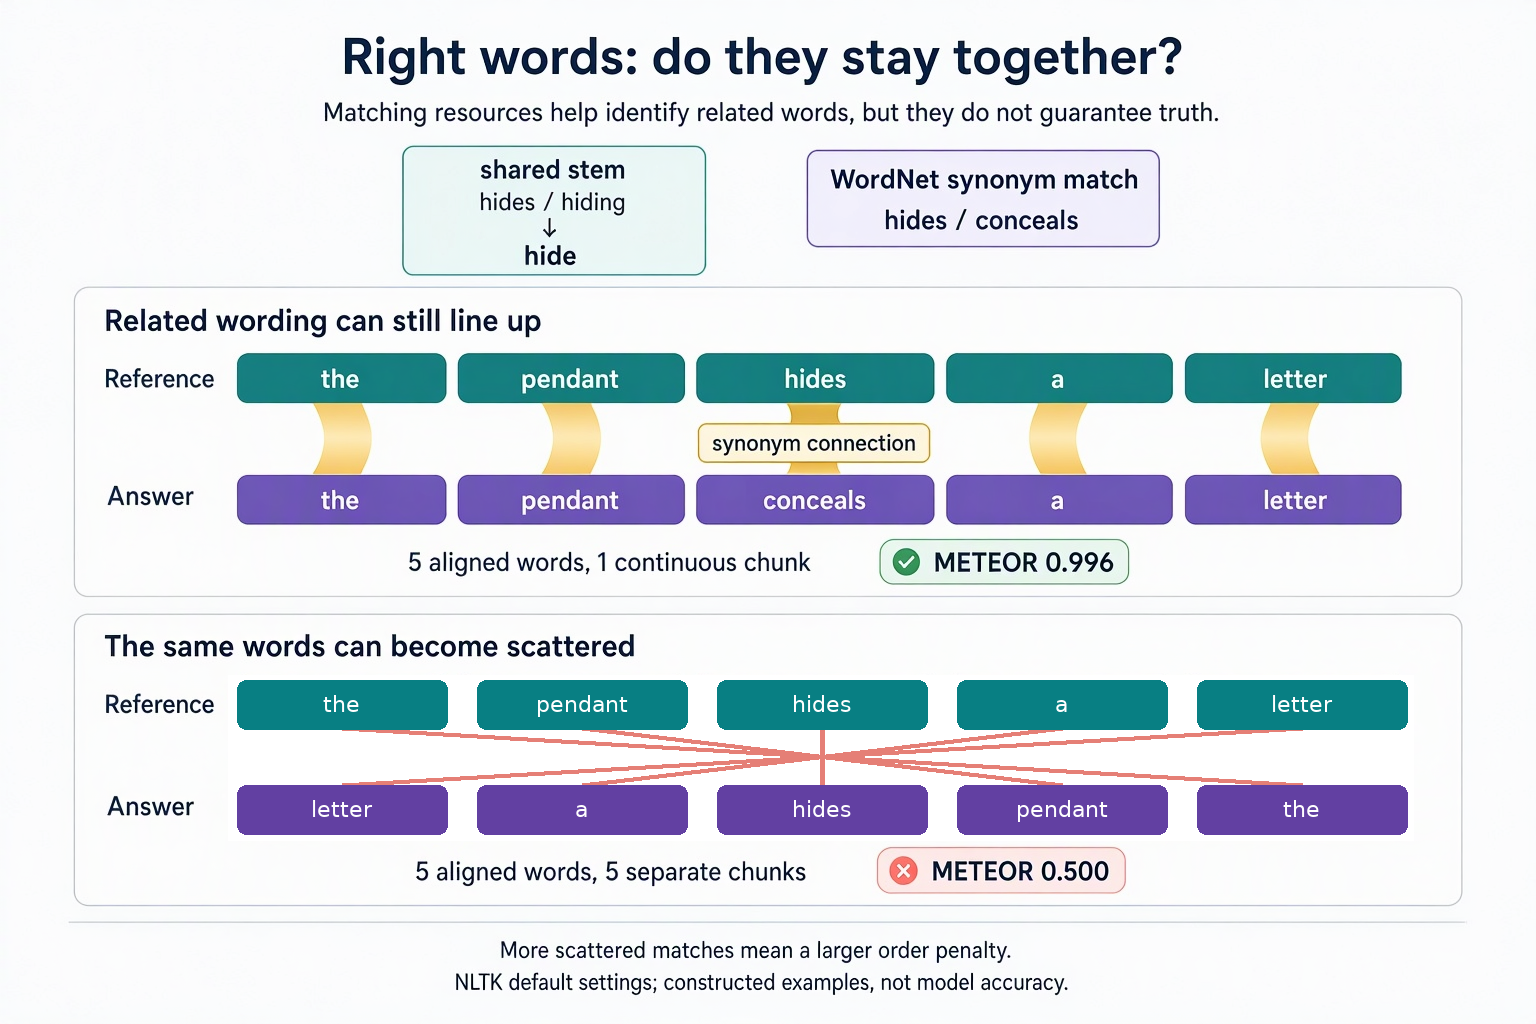


### Read one heatmap row before looking at the whole score

Choose an answer token on the left and read across its row. Darker cells mean closer contextual representations; gold marks its strongest reference match. `conceals` splits into `conceal` and `##s`, so a token need not be a whole word. These are actual DistilBERT similarities with special-token rows/columns hidden. MAI supplied the layout; code drew the measured panel.

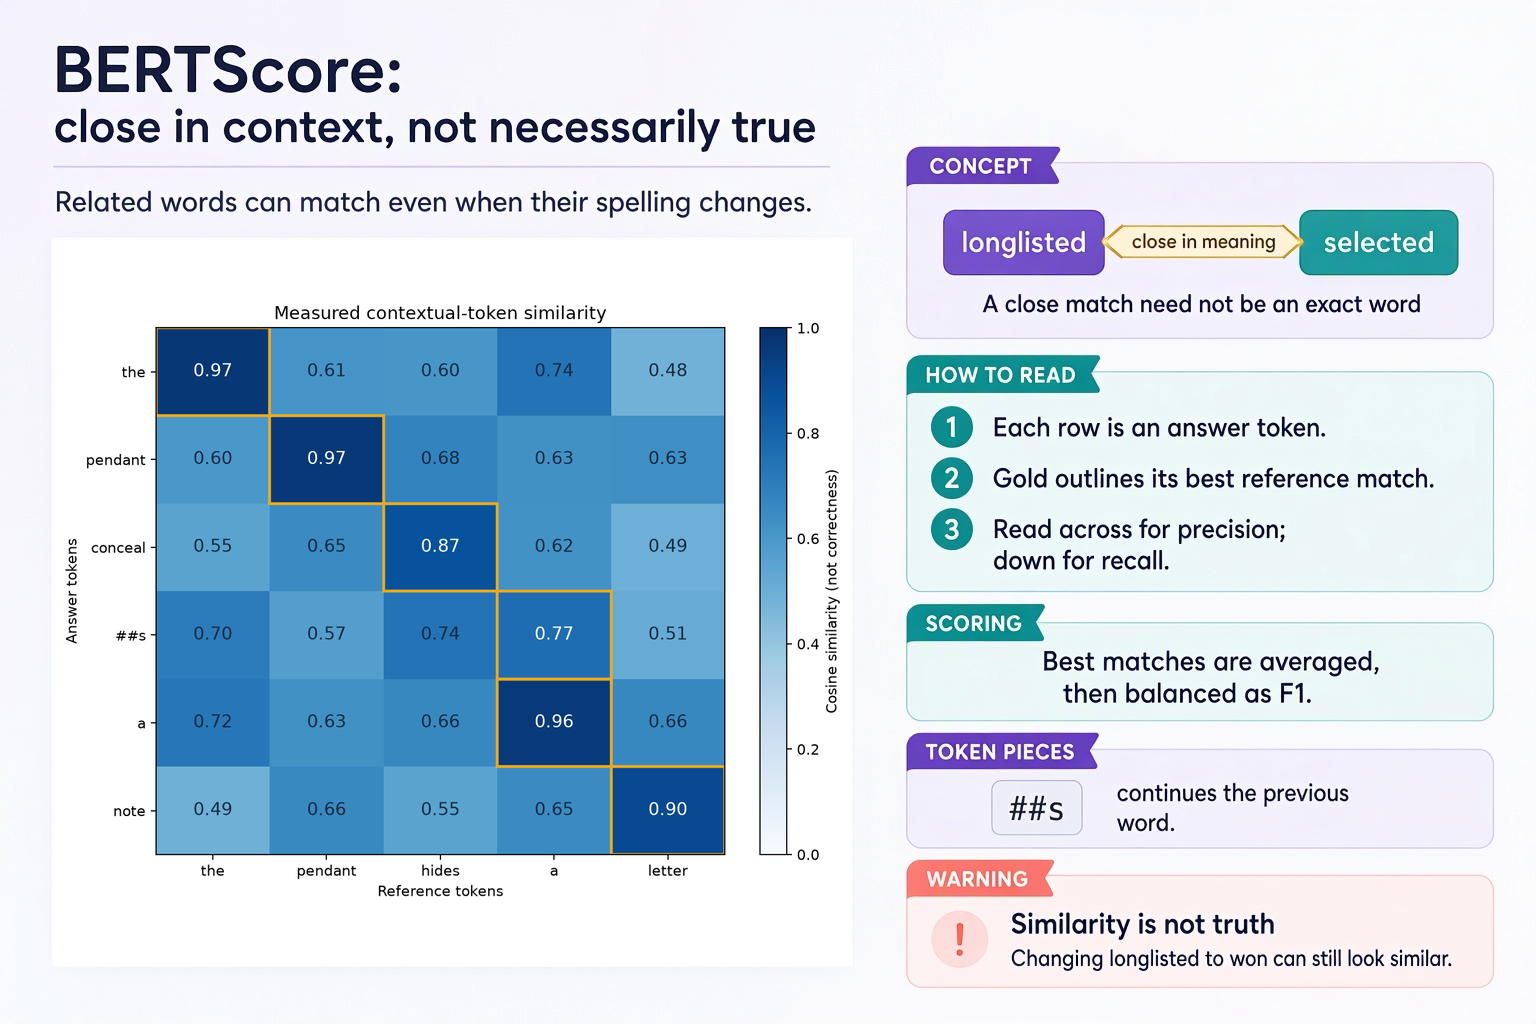


### Read the scores as answers to different questions

The [library helper](evaluation_metrics.py) scores every generated answer against its reference.
It keeps precision, recall and F1 where the library provides them.
It also records the exact settings, because changing the tokenizer or evaluator can
change the number.

Perplexity asks a separate question here:
**given the passage and question, how expected was the fixed reference answer?**
We hide the reference during generation, then supply it afterward for this separate measurement.
The prompt tokens are left out of the loss; only reference tokens count.
We do not grade the generated answer by how much the model likes its own guesses.

| Reading | How to read it here |
| --- | --- |
| ROUGE and METEOR | Between 0 and 1; more matching under that rule gives a higher value |
| BERTScore | Contextual-token similarity under the chosen encoder and settings; not a probability of correctness |
| BLEU | A 0-100 scale in this library |
| Reference perplexity | Lower means less surprise about the fixed reference, given the prompt |

Do not compare numbers across these columns as though they use one common scale.
None of them, alone, checks whether every generated claim is supported.

<a id="loss-probability-check"></a>

### A probability, a loss and perplexity are different numbers

The correct token's probability is between zero and one.
Ordinary cross-entropy charges more when that probability is small; its loss is **not**
restricted to that range. Perplexity converts the average token loss to a surprise scale.

Try a one-token microscope with just two possible answers. We choose the probabilities
by hand, then ask PyTorch to calculate the costs. These are controlled arithmetic inputs,
not new measurements of the pretrained model.

In [ ]:
loss_probe_probability = torch.tensor([0.9, 0.6, 0.1, 0.01], dtype=torch.float64)
# These scores have a softmax equal to the chosen two-class probabilities.
loss_probe_scores = torch.stack(
    (loss_probe_probability, 1 - loss_probe_probability), dim=1,
).log()
loss_probe_targets = torch.zeros(len(loss_probe_probability), dtype=torch.long)
loss_probe_losses = torch.nn.functional.cross_entropy(
    loss_probe_scores, loss_probe_targets, reduction="none",
)
loss_probe_table = pd.DataFrame({
    "correct_token_probability": loss_probe_probability.tolist(),
    "loss": loss_probe_losses.tolist(),
    "single_token_perplexity": loss_probe_losses.exp().tolist(),
    "top_choice_correct": loss_probe_scores.argmax(-1).eq(loss_probe_targets).tolist(),
})
display(loss_probe_table.round(3))

The 0.10 and 0.01 rows both choose the wrong top answer.
Their losses still differ: about **2.303** and **4.605**, with single-token perplexities
**10** and **100**. Accuracy alone does not show how little probability the correct
answer received. None of these numbers measures runtime efficiency.

The probabilities were hand-picked; the costs were calculated, not invented.
For a sequence, combine losses over the same valid reference tokens **before**
exponentiating. The real plot below does that for all 21 scored tokens.
Keep tokenizer, context and which tokens count fixed when comparing runs.

### Less expected tokens cost more

Start with the six token pieces above the bars: a small next-token probability produces a larger loss. The final average uses all 21 reference tokens, not just those six. These are actual SmolLM2 measurements for the pendant prompt; the prompt itself is not scored.

![The first six real reference-token pieces show their probabilities and losses, followed by a bar chart for all 21 scored reference tokens. Less expected tokens contribute larger losses. The mean loss produces perplexity about 5.609, conditioned on the exact pendant prompt.](attachment:01-metrics-perplexity.png)

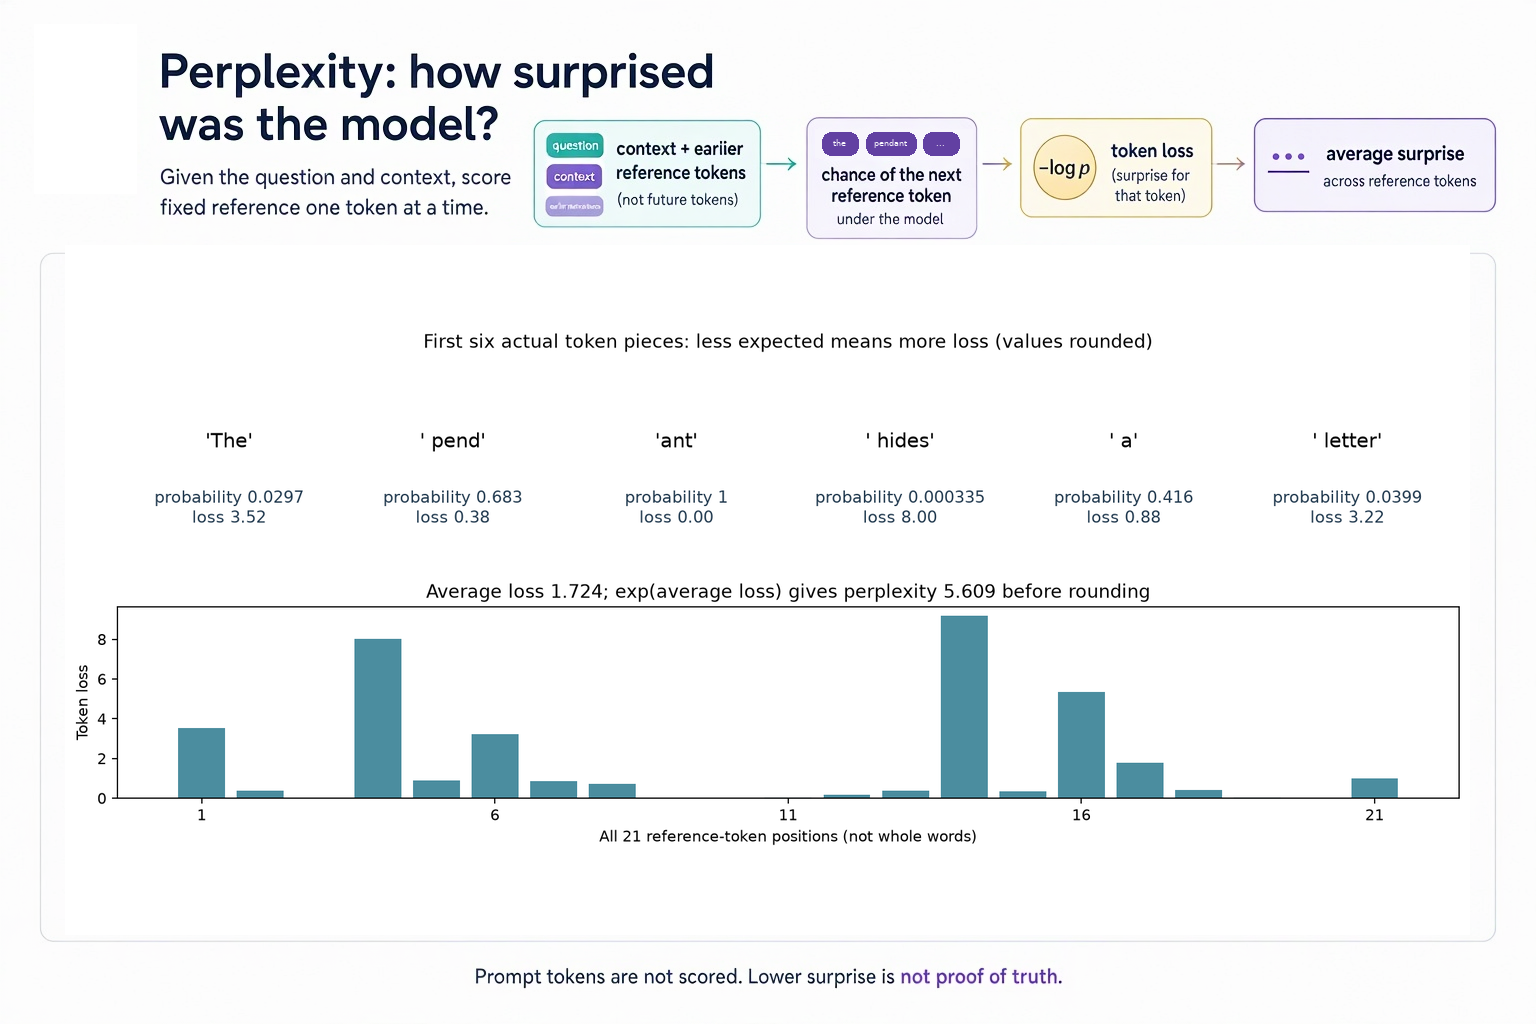

In [ ]:
prepare_wordnet()
encoder_path = download_snapshot(ENCODER_ID, ENCODER_REVISION)
# "rougeL" -> "rouge1"/"rouge2" changes the library match rule, not these test cases.
# BLEU-1/2/3 change max_ngram_order; keep smoothing and normalization recorded.
# BERTScore precision/recall/F1 reuse one set of token matches.
measured_items, measured_summary = score_answers(measured_answers, encoder_path)
measured_table = pd.DataFrame(measured_items)
columns = [
    "id", "rouge1_fmeasure", "rouge2_fmeasure", "rougeL_fmeasure",
    "bleu_0_100", "meteor", "bertscore_f1", "reference_ppl",
]
display(measured_table[columns].round(3))
detail_columns = ["id"] + [
    column for column in measured_table
    if column.startswith(("rouge", "bertscore"))
]
display(measured_table[detail_columns].round(3))
display(pd.DataFrame([measured_summary]).round(3))

### What happened in the saved CPU run?

These are actual results from the [retained run](results/metrics-cpu-smollm2-135m.json),
not sample values. The saved model revisions start `12fd25f` for SmolLM2 and
`12040ac` for DistilBERT; the record keeps the full versions, settings and answers.

| Case | ROUGE-1 F1 | ROUGE-2 F1 | ROUGE-L F1 | BLEU /100 | METEOR | BERTScore F1 | Reference PPL |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| pendant | 0.524 | 0.300 | 0.429 | 15.083 | 0.605 | 0.851 | 5.609 |
| award | 0.533 | 0.286 | 0.400 | 10.831 | 0.682 | 0.808 | 1.627 |
| react | 0.400 | 0.061 | 0.343 | 5.238 | 0.407 | 0.866 | 2.195 |
| rights | 0.640 | 0.522 | 0.640 | 48.634 | 0.730 | 0.885 | 6.499 |
| Aggregate | 0.524 | 0.292 | 0.453 | 17.402 | 0.606 | 0.853 | 3.351 |

Now look at the answer, not just its score:

1. **Award:** the passage says `longlisted`. The model says `won` and adds the title
   *The Lost City of the Ancients*, which the passage never supplied.
   BERTScore is still **0.808**. It sees substantial contextual similarity;
   it does not mean that 80.8% of the facts are correct.
2. **Rights:** the passage requires review **before licensing excerpts externally**.
   The answer requires review **before translating**. Much wording survives, and
   ROUGE-L is **0.640**, but the policy condition has changed.

The award reference also has low perplexity, **1.627**. That is not a contradiction:
the model found the supplied correct reference predictable when we scored it,
yet produced a different answer when generating for itself.

**How the bottom row is made:** ROUGE, METEOR and BERTScore are averaged over cases.
BLEU is calculated across the corpus, not obtained by averaging sentence scores.
Reference-token losses are combined before converting their average to perplexity.
The full precision/recall/F1 readings remain in the live tables and saved JSON.

### Your turn - change one answer, not the whole experiment

The next cell substitutes our prewritten valid `pendant` answer and reruns the scorers.
It does not generate again. Predict which readings should move.
Reference perplexity must stay fixed: its prompt, reference and model have not changed.
Then try `fluent_wrong` in that one place and inspect the same comparison.

Using a test set to adjust answers or prompts makes it part of development.
Do not present the resulting scores on that same set as a fresh independent test.

In [ ]:
changed_answers = [dict(row) for row in measured_answers]
changed_answers[0]["answer"] = RIVERSIDE_CASES[0]["candidate"]
# Your turn: choose "fluent_wrong" instead; change no reference, prompt or model.
changed_items, _ = score_answers(changed_answers, encoder_path)
display(pd.DataFrame([
    {"reading": column, "before": measured_items[0][column], "after": changed_items[0][column]}
    for column in columns[1:]
]).round(3))
assert changed_items[0]["reference_ppl"] == measured_items[0]["reference_ppl"]
print("Only the answer changed; fixed-reference perplexity stayed unchanged.")

<a id="multiple-reference-check"></a>

### What if two wordings are acceptable?

The reversal drill has one required ordering. An open-ended answer can say the same
supported thing in several ways, so one reference may cover only one accepted wording.

Keep the real generated pendant answer fixed. Compare it with the original reference,
then with that reference plus the valid `candidate` paraphrase already present in our
fixture before this model run. We do not turn the model's answer into its own reference
or write a new reference to chase its score.

This is a separate sensitivity check using the existing BLEU library, not a new
translation benchmark or a replacement for the retained one-reference report.

In [ ]:
from sacrebleu.metrics import BLEU

reference_probe_case = next(case for case in RIVERSIDE_CASES if case["id"] == "pendant")
reference_probe_answer = next(row["answer"] for row in measured_answers if row["id"] == "pendant")
reference_probe_scorer = BLEU(tokenize="none", smooth_method="exp", effective_order=True)
reference_probe_rows = []
for reference_probe_references in (
    [reference_probe_case["reference"]],
    [reference_probe_case["reference"], reference_probe_case["candidate"]],
):
    reference_probe_value = reference_probe_scorer.sentence_score(
        " ".join(tokenize(reference_probe_answer)),
        [" ".join(tokenize(reference)) for reference in reference_probe_references],
    )
    reference_probe_rows.append({
        "accepted_wordings": len(reference_probe_references), "bleu_0_100": reference_probe_value.score,
    })
print("The same generated answer:", reference_probe_answer)
display(pd.DataFrame(reference_probe_rows).round(3))

On the retained generated answer, the score moves from about **15.083** to **15.415**.
That modest change comes from the reference protocol, not improved model weights or
a newly generated answer. The added wording still shares only some of the answer's phrases.

Adding references is not a guarantee of a high score or factual correctness.
Choose and review reference sets before comparing systems, and version that choice with
the results. The old score table remains the original one-reference experiment.

## Part 5 - Did the average hide a failure we care about?

Suppose a candidate answers more questions correctly overall. Before calling it better,
check which questions improved and which still fail.

Below, a **slice** just means a group: manuscript questions, evaluation questions, or
a critical policy question. The six answer records are declared examples, not more
generations from the model. They let us see the arithmetic without mistaking a toy
comparison for another capability result.

In [ ]:
# Fixed six-item example with three question groups.
benchmark = [
    {"id": "b1", "slice": "manuscript", "gold": "B", "baseline": "A", "candidate": "B"},
    {"id": "b2", "slice": "manuscript", "gold": "C", "baseline": "C", "candidate": "C"},
    {"id": "b3", "slice": "manuscript", "gold": "A", "baseline": "D", "candidate": "A"},
    {"id": "b4", "slice": "evaluation", "gold": "B", "baseline": "B", "candidate": "B"},
    {"id": "b5", "slice": "evaluation", "gold": "D", "baseline": "D", "candidate": "C"},
    {"id": "b6", "slice": "critical policy", "gold": "A", "baseline": "B", "candidate": "B"},
]
benchmark_rows = []
for item in benchmark:
    for system in ["baseline", "candidate"]:
        benchmark_rows.append({
            "item_id": item["id"], "slice": item["slice"], "system": system,
            "prediction": item[system], "gold": item["gold"],
            "correct": item[system] == item["gold"],
        })
benchmark_records = pd.DataFrame(benchmark_rows)
display(benchmark_records)


In [ ]:
# Aggregate only after the critical-policy miss remains visible.
slice_accuracy = benchmark_records.groupby(["system", "slice"])["correct"].mean().unstack()
overall_accuracy = benchmark_records.groupby("system")["correct"].mean()
display(slice_accuracy)
display(overall_accuracy.to_frame("overall_accuracy"))
assert not benchmark_records.query(
    "system == 'candidate' and slice == 'critical policy'"
)["correct"].all()
print("A candidate gain cannot average away a critical-policy miss.")


### Better overall, still wrong on the policy question

The baseline gets three of six answers right; the candidate gets four of six.
But the candidate still misses the one policy item, `b6`.

The final assertion deliberately checks that this example still contains that miss.
It is a demonstration of a failure we must not hide, **not** a release gate approving
the candidate. A real decision needs a policy for which failures are unacceptable.

## Exercise - fix one evaluation question

Use item **`b5`**, not the policy item `b6`, for this exercise.
Keeping `b6` unchanged lets the example continue to demonstrate the policy miss.

1. **Predict:** the `evaluation` group contains two questions; the whole table contains six.
   How much should each accuracy move if only `b5` is repaired?
2. **Change:** in the `benchmark` definition, change only `b5`'s `candidate` answer from
   `C` to its correct answer `D`. Leave every other entry and rule unchanged.
3. **Measure:** rerun the benchmark-record cell and the following accuracy cell.
   Compare the `evaluation` group, overall accuracy, and the unchanged policy result.
4. **Diagnose:** explain why one correction has a larger effect inside a small group
   than in the overall average.
5. **Explain:** state what improved in this declared example and what still blocks
   approval. Do not turn one repaired row into a claim about all future questions.

## What did we learn?

- Matching words is a useful check, not a fact check.
- Related ROUGE and BLEU choices change the patterns counted. They are not a ranking
  from an old, bad metric to a new, universally better one.
- A manual word-grouping toy and a pretrained contextual encoder are different tools.
- A model can find the correct reference predictable and still generate an unsupported answer.
- An overall gain cannot erase a failed policy question.
- Keep the answers, per-case readings, settings and versions so another person can
  inspect what the score actually means.

| What we can claim | What supports it here |
| --- | --- |
| We ran these checks | Manual ROUGE-L, the small word-count/bigram examples, and real CPU generation scored with ROUGE-1/2/L, BLEU-4, METEOR, BERTScore and reference perplexity |
| We explained these alternatives without separately running them | ROUGE-S, BLEU-1/2/3, and local checkpoint-loading choices |
| We have not established this | A local adapter is better, the model is generally accurate, or the system is ready for release |

The unanswered question is trust: **if another model grades these answers, who checks that grader?**
[Part 2](02-llm-as-judge-safety-and-pipeline.ipynb) tests judge instructions, order effects,
human agreement and safety. [Part 3](03-hallucination-detection.ipynb) checks support for individual claims.

<a id="concept-recap"></a>

## Concept recap

First decide what a score should tell you. Then keep the question, supplied passage,
accepted reference and actual answer together.
These code sketches reuse earlier names and imports; they are notes on the ideas,
not a standalone evaluation program.

### Count wording without calling it truth

ROUGE-1 counts words, ROUGE-2 counts neighboring pairs, and ROUGE-L finds wording
kept in order, allowing gaps. Swap the matching rule, not the test cases.

```python
rouge = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"], tokenizer=LessonTokenizer()
)
scores = rouge.score(reference, answer)
```

Precision asks how much of the produced wording matched. Recall asks how much
reference wording was recovered. F1 balances both; zero matches give zero F1.

```python
precision = matches / max(produced, 1)
recall = matches / max(required, 1)
f1 = 0 if precision + recall == 0 else (
    2 * precision * recall / (precision + recall)
)
```

### Ask what a different metric adds

BLEU caps repeated matches and penalizes answers that are too short.
Its numbered variants change the largest phrase length.
METEOR can match stems and synonyms, then penalizes scattered matches.
Neither establishes that the answer's claims follow from the passage.

```python
from sacrebleu.metrics import BLEU
from nltk.translate.meteor_score import meteor_score

bleu = BLEU(tokenize="none", smooth_method="exp", effective_order=True)
meteor_value = meteor_score([reference_terms], candidate_terms)
```

Keep the normalization and settings with the number. Corpus BLEU is not the average
of sentence BLEU scores.

### Similarity asks whether wording is close

BERTScore compares token representations that depend on the surrounding sentence.
For a NumPy similarity array, the simplified unweighted idea is:

```python
precision = similarities.max(axis=1).mean()
recall = similarities.max(axis=0).mean()
```

Rows are answer tokens; columns are reference tokens. The library handles token masks
and its configured weighting. An unsupported award claim can still look close to its
reference: **0.808 similarity is not 80.8% factual correctness.**

### Perplexity asks how expected the reference was

Here we score the fixed reference after giving the model its prompt. Prompt tokens
do not contribute to the loss. Combine reference-token losses before converting to perplexity.

```python
mean_loss = total_reference_loss / reference_token_count
perplexity = math.exp(mean_loss)
```

The model can find that reference predictable and still generate a different answer.
Keep individual results and question groups beside the average, with model, evaluator,
tokenizer and data versions. Four visible practice cases are not a release certificate.

**Remember:** overlap checks wording; contextual similarity checks closeness;
perplexity checks expectation; factual review checks support.
Next, ask [whether we can trust the evaluator](02-llm-as-judge-safety-and-pipeline.ipynb).